# 03 · Customer Retention & Segmentation

**Questions:** Do customers come back? How fast? Does a good first experience make them return?
Which customers are worth targeting?

Data: `analysis.cohort_retention`, `analysis.repeat_purchase_summary`, `analysis.customer_rfm`, `marts.fact_orders`.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from ecom import viz
from ecom.db import query, table

viz.set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)

In [ ]:
table("analysis.repeat_purchase_summary").T.rename(columns={0: "value"})

,value
customers,"96,096.00"
repeat_customers,"2,997.00"
repeat_rate_pct,3.12
median_days_to_second_order,28.00
same_day_repeat_pct,29.93


## 1. Cohort retention

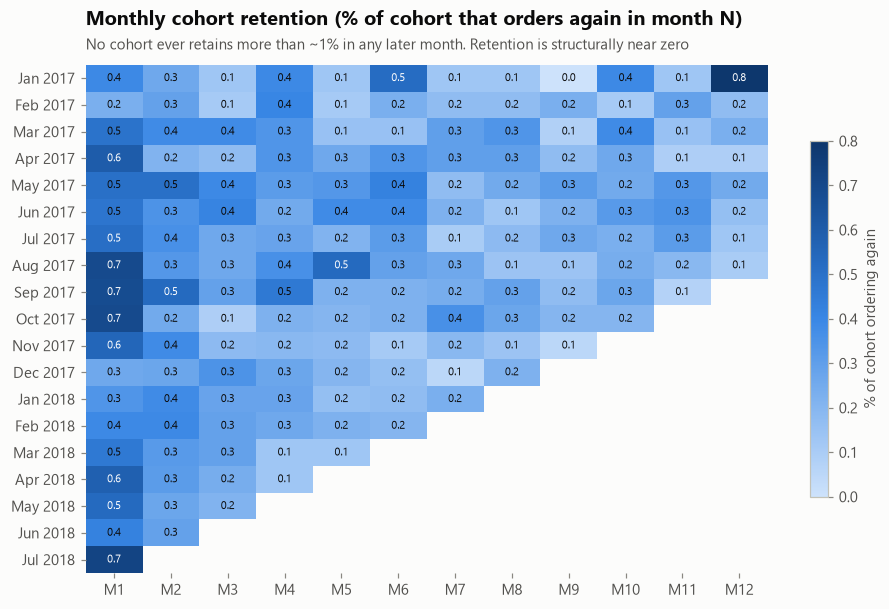

Average retention, months 1–12: 0.28%


In [ ]:
cr = table("analysis.cohort_retention")
heat = cr.query("months_since_first.between(1, 12)").pivot(
    index="cohort_month", columns="months_since_first", values="retention_pct"
)
# Inside the observable range, a missing cell means nobody came back (0%), not "no data".
last = pd.Timestamp(cr["cohort_month"].max())
for cohort in heat.index:
    horizon = (last.year - cohort.year) * 12 + (last.month - cohort.month)
    observable = [c for c in heat.columns if c <= horizon]
    heat.loc[cohort, observable] = heat.loc[cohort, observable].fillna(0)
heat.index = pd.to_datetime(heat.index).strftime("%b %Y")

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(heat, aspect="auto", cmap=viz.SEQ_CMAP, vmin=0, vmax=0.8)
ax.set_xticks(range(heat.shape[1]), [f"M{c}" for c in heat.columns])
ax.set_yticks(range(heat.shape[0]), heat.index)
for (i, j), v in np.ndenumerate(heat.to_numpy()):
    if not np.isnan(v):
        ax.text(
            j,
            i,
            f"{v:.1f}",
            ha="center",
            va="center",
            fontsize=7.5,
            color="white" if v > 0.5 else viz.INK,
        )
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="% of cohort ordering again")
ax.set_title("Monthly cohort retention (% of cohort that orders again in month N)")
viz.subtitle(
    ax,
    "No cohort ever retains more than ~1% in any later month. Retention is structurally near zero",
)
viz.save(fig, "cohort_retention")
plt.show()

print(
    f"Average retention, months 1–12: {cr.query('months_since_first.between(1, 12)')['retention_pct'].mean():.2f}%"
)

## 2. When repeat customers come back

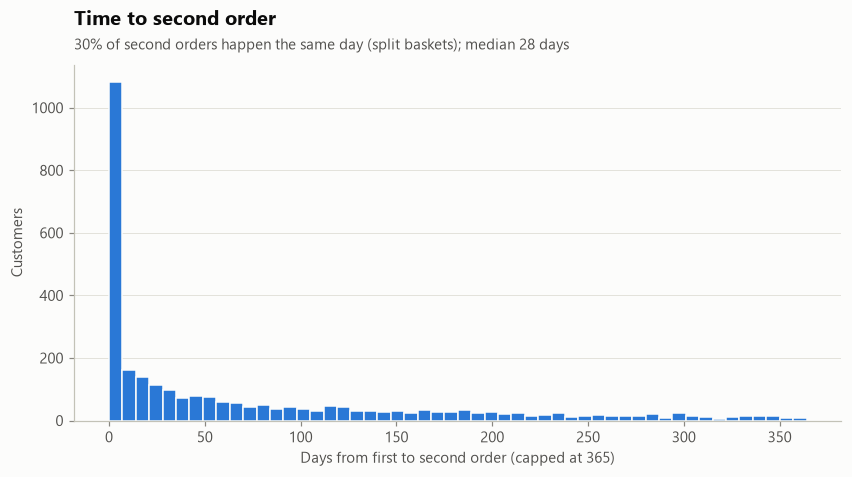

In [ ]:
gaps = query("""
    WITH s AS (
        SELECT customer_unique_id,
               date_diff('day',
                   min(order_purchase_timestamp) FILTER (WHERE customer_order_seq = 1),
                   min(order_purchase_timestamp) FILTER (WHERE customer_order_seq = 2)) AS days
        FROM marts.fact_orders GROUP BY 1
    )
    SELECT days FROM s WHERE days IS NOT NULL
""")["days"]

fig, ax = plt.subplots()
ax.hist(
    gaps.clip(upper=365),
    bins=np.arange(0, 370, 7),
    color=viz.BLUE,
    edgecolor=viz.SURFACE,
    linewidth=1,
)
ax.set_xlabel("Days from first to second order (capped at 365)")
ax.set_ylabel("Customers")
ax.set_title("Time to second order")
viz.subtitle(
    ax,
    f"{(gaps == 0).mean():.0%} of second orders happen the same day (split baskets); median {gaps.median():.0f} days",
)
viz.save(fig, "time_to_second_order")
plt.show()

Almost a third of "repeat" orders are the **same day**: customers splitting one basket across sellers.
That is not loyalty, so the *true* repeat rate is closer to **~2%**.

## 3. Does a good first experience bring customers back?

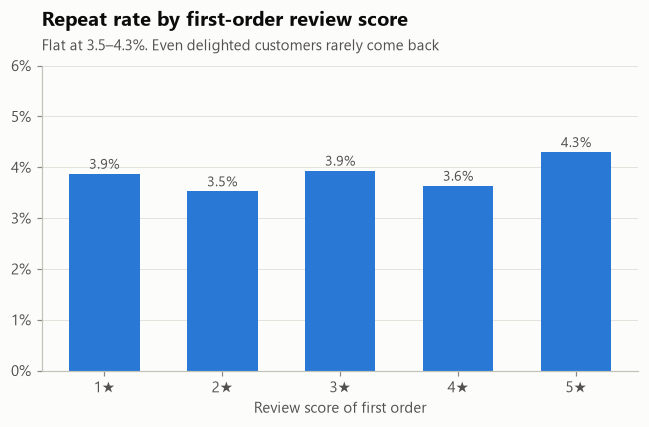

Chi-square p-value (score vs repeat): 0.020


,repeat_rate,customers
review_score,,
1,3.87,5429
2,3.52,1760
3,3.93,4784
4,3.63,11011
5,4.30,31803


In [ ]:
first = query("""
    SELECT f.review_score, f.is_late, c.lifetime_orders > 1 AS repeated
    FROM marts.fact_orders f JOIN marts.dim_customer c USING (customer_unique_id)
    WHERE f.customer_order_seq = 1 AND f.is_delivered AND f.in_analysis_window
      AND f.purchase_date < DATE '2018-03-01'   -- leave >= 6 months to observe a repeat
""")
by_score = first.groupby("review_score")["repeated"].agg(repeat_rate="mean", customers="size")
by_score["repeat_rate"] *= 100

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(
    by_score.index.astype(int).astype(str) + "★", by_score["repeat_rate"], color=viz.BLUE, width=0.6
)
for x, v in enumerate(by_score["repeat_rate"]):
    ax.text(x, v + 0.1, f"{v:.1f}%", ha="center", fontsize=9, color=viz.INK_2)
ax.yaxis.set_major_formatter(viz.PCT)
ax.set_ylim(0, 6)
ax.set_xlabel("Review score of first order")
ax.set_title("Repeat rate by first-order review score")
viz.subtitle(ax, "Flat at 3.5–4.3%. Even delighted customers rarely come back")
plt.show()

chi = stats.chi2_contingency(pd.crosstab(first["review_score"], first["repeated"]))
print(f"Chi-square p-value (score vs repeat): {chi.pvalue:.3f}")
by_score

**A key nuance:** the link between first-order score and repeat purchase is statistically detectable (p = 0.02),
but tiny in practice (3.5–4.3%), and not even monotonic. First-order satisfaction barely moves repeat behaviour. Olist is a marketplace that customers
reach through product searches, not a brand they return to. Retention will not fix itself through better service alone;
it needs **active CRM** (email, cross-sell, loyalty incentives).

## 4. RFM segments: who to target

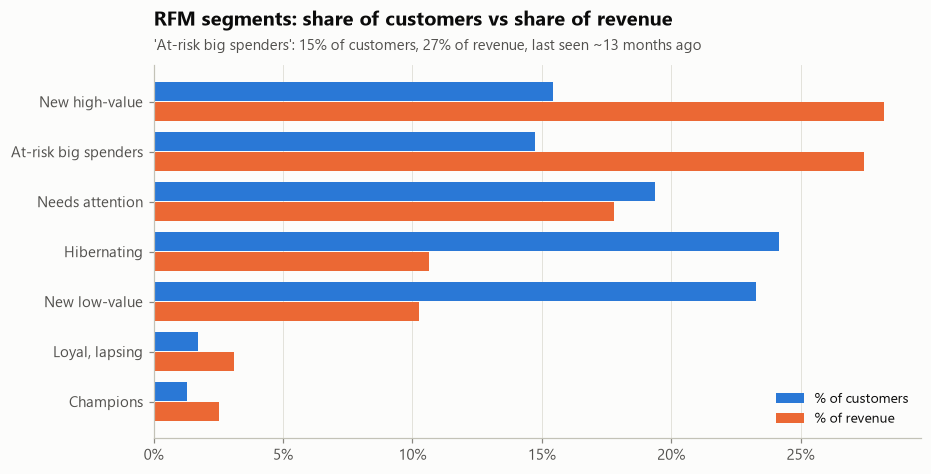

,segment,customers,customer_share_pct,revenue,revenue_share_pct,avg_monetary,avg_recency_days,avg_frequency
0,New high-value,14373,15.44,"4,340,691.55",28.24,302.00,94.00,1.00
1,At-risk big spenders,13733,14.75,"4,221,670.78",27.46,307.41,394.00,1.00
2,Needs attention,18021,19.36,"2,733,408.63",17.78,151.68,222.00,1.00
3,Hibernating,22510,24.18,"1,636,118.37",10.64,72.68,396.00,1.00
4,New low-value,21670,23.28,"1,579,318.57",10.27,72.88,92.00,1.00
5,"Loyal, lapsing",1594,1.71,"474,460.75",3.09,297.65,321.00,2.08
6,Champions,1195,1.28,"386,072.44",2.51,323.07,91.00,2.15


In [ ]:
seg = table("analysis.rfm_segment_summary").sort_values("revenue_share_pct")

fig, ax = plt.subplots(figsize=(9, 4.4))
y = np.arange(len(seg))
ax.barh(y + 0.2, seg["customer_share_pct"], height=0.38, color=viz.BLUE, label="% of customers")
ax.barh(y - 0.2, seg["revenue_share_pct"], height=0.38, color=viz.ORANGE, label="% of revenue")
ax.set_yticks(y, seg["segment"])
ax.xaxis.set_major_formatter(viz.PCT)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.legend(loc="lower right")
ax.set_title("RFM segments: share of customers vs share of revenue")
viz.subtitle(
    ax, "'At-risk big spenders': 15% of customers, 27% of revenue, last seen ~13 months ago"
)
viz.save(fig, "rfm_segments")
plt.show()

table("analysis.rfm_segment_summary")

## Findings

1. **Retention is the #1 business problem.** Only **3.1%** of 96K customers ever order again (true loyalty ~2% after removing same-day split baskets),
   and monthly cohort retention never exceeds ~1%.
2. **Service quality alone won't fix it.** First-order review score shifts the repeat rate by under 1 point (3.5–4.3%).
3. **Value is concentrated in lapsing customers.** *At-risk big spenders* (13.7K customers, R$307 average) hold 27% of revenue, and
   *New high-value* (14.4K) another 28%.

## Recommendations (with how to measure them)

| Action | Target segment | Success metric |
|---|---|---|
| Win-back campaign with a category-matched voucher | At-risk big spenders (13.7K) | Reactivation rate vs. a 10% hold-out group |
| "Second order within 30 days" onboarding flow (the median gap is 28 days) | New high-value (14.4K) | 60-day repeat rate, A/B tested |
| Cross-sell from the first order's category | All new customers | Second-order conversion |
| Low-cost channels only (no paid incentives) | Hibernating / New low-value | Cost per reactivated customer |